In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import io
import numpy as np
import math

In [3]:
model_output = """100000         77       1471      0.934      0.871      0.925      0.759
010000         69        419       0.89      0.716      0.819      0.645
110000         78        521      0.861       0.83      0.874      0.725
001000         27        162      0.744      0.451      0.534       0.44
101000         72        720      0.927      0.844      0.907       0.76
011000         23        307      0.764      0.601      0.632      0.535
111000         76        776      0.944      0.899      0.938      0.798
000100         19         77      0.788      0.145       0.29      0.237
100100         57        184      0.928       0.77      0.872      0.694
010100         78       1414      0.819      0.757      0.827      0.706
110100         40        159      0.514      0.214      0.325      0.266
001100         22        229      0.788      0.629      0.686        0.6
101100         74        564      0.916      0.856      0.913      0.785
011100         74        768       0.88      0.793      0.871       0.75
111100         65        487      0.935      0.893      0.937      0.812
000010         20       1008      0.884      0.521      0.711      0.529
100010         73       1339      0.806      0.703      0.785      0.665
010010         48        542      0.958      0.889      0.941      0.534
110010         72        598      0.776      0.689       0.72      0.627
001010         21        143      0.741      0.413      0.579      0.506
101010         76       1520      0.924       0.92      0.947      0.815
011010         55        193      0.391      0.223      0.221      0.181
111010         67        687      0.733      0.626      0.721       0.63
000110         16         77      0.637       0.39      0.485      0.342
100110         77        864      0.855      0.803      0.854      0.736
010110         71        281      0.525      0.311      0.377      0.319
110110         76        606      0.963      0.917      0.954       0.83
001110         25        110      0.601       0.63      0.524      0.444
101110         74        908      0.811      0.757      0.804      0.694
011110         75       1007      0.853      0.831      0.876      0.756
111110         68        281      0.884       0.73      0.813      0.708
000001         14         55      0.166     0.0545      0.103      0.056
100001         34        133      0.491     0.0943      0.281      0.245
010001         34        243      0.859      0.627      0.744       0.65
110001         23         80       0.46      0.175      0.259      0.215
001001         69        381      0.912      0.798      0.883      0.703
101001         75        695      0.873       0.81      0.862      0.747
011001         31        101       0.55      0.396      0.424      0.378
111001         22        145      0.503      0.152      0.218      0.197
000101         22         36      0.971      0.278      0.606      0.448
100101         21        127      0.835      0.598      0.685      0.607
010101         36        113      0.508      0.133      0.242      0.211
110101         64        289       0.47      0.336      0.387      0.326
001101         21         97      0.274     0.0352      0.243      0.204
101101         40        145      0.947      0.724      0.841      0.737
011101         64        334      0.771      0.674      0.738      0.646
111101         63        226      0.898      0.757      0.846      0.733
000011         15        125      0.553      0.152      0.317      0.258
100011         66        433      0.795      0.674      0.733      0.641
010011         75        427      0.701      0.644      0.666      0.536
110011         55        167      0.637      0.108       0.25      0.218
001011         33        114      0.526      0.351      0.366      0.307
101011         69        337      0.706      0.611      0.683      0.604
011011         22        106       0.84      0.736      0.816      0.613
111011         26         97      0.649      0.412      0.483      0.418
000111         12         59      0.832      0.525      0.679      0.373
100111         12         41       0.81      0.293      0.547      0.464
010111         74        749      0.786      0.638      0.739      0.632
110111         17         34      0.416      0.147      0.273      0.235
001111         65        480      0.798      0.819      0.843       0.66
101111         10         29      0.415      0.241      0.297      0.282
011111         63        308       0.87      0.795      0.855       0.75
111111         23         63      0.938       0.81      0.883      0.731"""

In [ ]:
data = io.StringIO(model_output)
rows = [x.split() for x in data.readlines()]

class_labels = [row[0] for row in rows]
images = [int(row[1]) for row in rows]
instances = [int(row[2]) for row in rows]
precision = [float(row[3]) for row in rows]
recall = [float(row[4]) for row in rows]
mAP50 =  [float(row[5]) for row in rows]
mAP50_95 = [float(row[6]) for row in rows]

['100000', '010000', '110000', '001000', '101000', '011000', '111000', '000100', '100100', '010100', '110100', '001100', '101100', '011100', '111100', '000010', '100010', '010010', '110010', '001010', '101010', '011010', '111010', '000110', '100110', '010110', '110110', '001110', '101110', '011110', '111110', '000001', '100001', '010001', '110001', '001001', '101001', '011001', '111001', '000101', '100101', '010101', '110101', '001101', '101101', '011101', '111101', '000011', '100011', '010011', '110011', '001011', '101011', '011011', '111011', '000111', '100111', '010111', '110111', '001111', '101111', '011111', '111111']


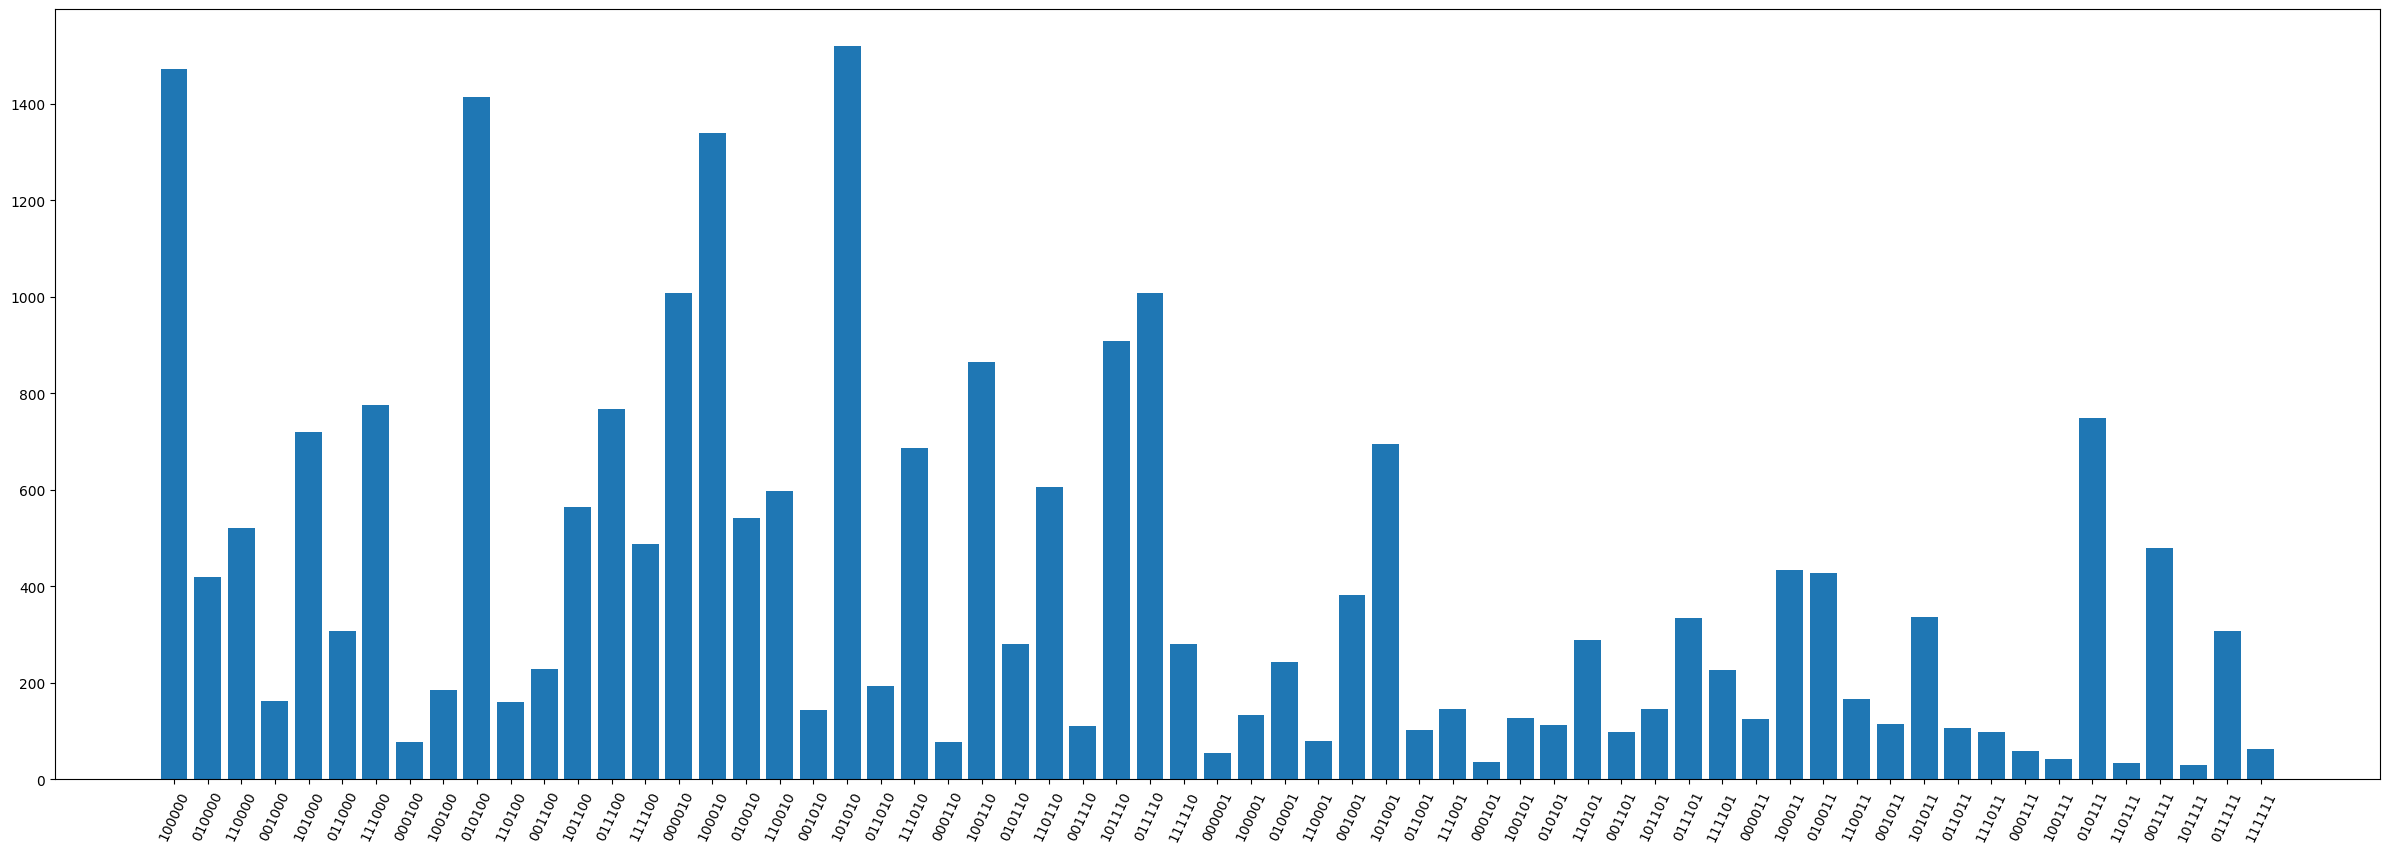

In [41]:
x = np.arange(len(class_labels))

plt.figure(figsize=(30, 10))

# ax.bar(x - width/2, images_norm, width, label="Images (norm)")
plt.bar(x=class_labels, label="Instances", height=instances)
plt.xticks(rotation=65, size=10)

plt.show()

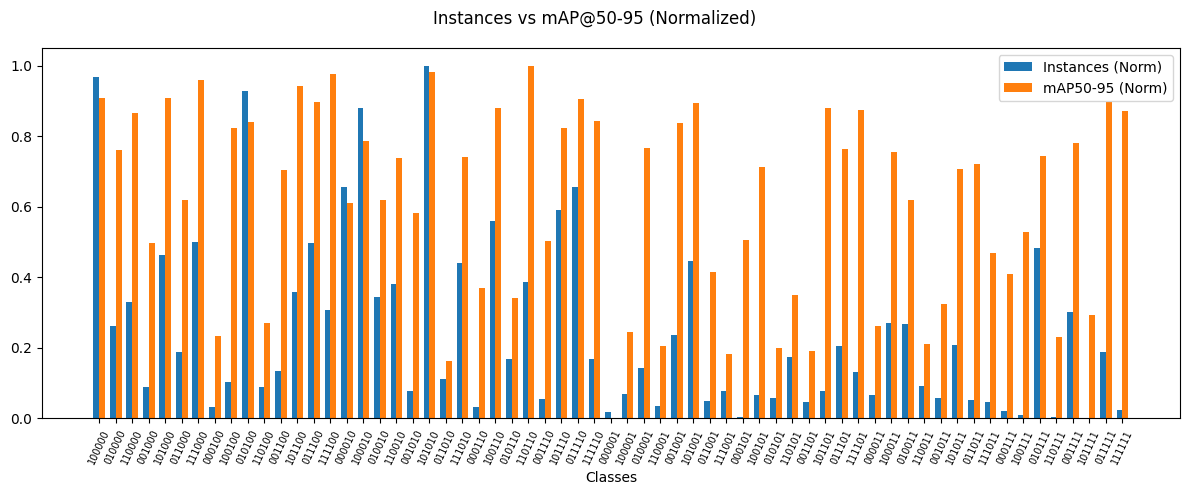

In [38]:
x = np.arange(len(class_labels))

instances_norm = [(x - min(instances)) / (max(instances) - min(instances)) for x in instances ]
mAP50_95_norm = [(x - min(mAP50_95)) / (max(mAP50_95) - min(mAP50_95)) for x in mAP50_95 ]

width = 0.35

plt.figure(figsize=(12, 5))

plt.bar(x - width/2, instances_norm, width, label='Instances (Norm)')
plt.bar(x + width/2, mAP50_95_norm, width, label='mAP50-95 (Norm)')

plt.xticks(x, class_labels, rotation=65, size=7)
plt.xlabel("Classes")
plt.suptitle('Instances vs mAP@50-95 (Normalized)')
plt.legend()

plt.tight_layout()
plt.show()

In [23]:
## Pearson's Correlation Coefficient

def corr_coeff(x, y):
    if(len(x) != len(y)):
        print("Error: number of data are not equal")
        return
    
    n = len(x)

    x= np.array(x)
    y = np.array(y)

    return (n*(sum(x*y)) - (sum(x) * sum(y)))/(math.sqrt((n*sum(np.pow(x, 2)) - math.pow(sum(x),2))*(n*sum(np.pow(y, 2)) - math.pow(sum(y),2))))

print("Correlation Coefficient between Instances and mAP@50-90:", corr_coeff(instances, mAP50_95))

Correlation Coefficient between Instances and mAP@50-90: 0.6100058998600376
